In [7]:
import pandas as pd
import numpy as np  

test = pd.read_csv('student-mat.csv', sep=';')
test.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [10]:
train = pd.read_csv('student-mat.csv' , sep=';')
train.head

<bound method NDFrame.head of     school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
0       GP   F   18       U     GT3       A     4     4   at_home   teacher   
1       GP   F   17       U     GT3       T     1     1   at_home     other   
2       GP   F   15       U     LE3       T     1     1   at_home     other   
3       GP   F   15       U     GT3       T     4     2    health  services   
4       GP   F   16       U     GT3       T     3     3     other     other   
..     ...  ..  ...     ...     ...     ...   ...   ...       ...       ...   
390     MS   M   20       U     LE3       A     2     2  services  services   
391     MS   M   17       U     LE3       T     3     1  services  services   
392     MS   M   21       R     GT3       T     1     1     other     other   
393     MS   M   18       R     LE3       T     3     2  services     other   
394     MS   M   19       U     LE3       T     1     1     other   at_home   

     ... famrel freet

Data Cleaning dan Transformation

In [11]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [12]:
# 1. # Menampilkan statistik deskriptif dari dataset
train.describe(include='all')

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395,395,395.000000,395,395,395,395.000000,395.000000,395,395,...,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
unique,2,2,NaN,2,2,2,NaN,NaN,5,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,GP,F,NaN,U,GT3,T,NaN,NaN,other,other,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,349,208,NaN,307,281,354,NaN,NaN,141,217,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,16.696203,NaN,NaN,NaN,2.749367,2.521519,NaN,NaN,...,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,NaN,NaN,1.276043,NaN,NaN,NaN,1.094735,1.088201,NaN,NaN,...,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,NaN,NaN,15.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,NaN,NaN,16.000000,NaN,NaN,NaN,2.000000,2.000000,NaN,NaN,...,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,NaN,NaN,17.000000,NaN,NaN,NaN,3.000000,2.000000,NaN,NaN,...,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,NaN,NaN,18.000000,NaN,NaN,NaN,4.000000,3.000000,NaN,NaN,...,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000


In [15]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]


Series([], dtype: int64)

In [16]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [17]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [19]:
#Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object']).columns
for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

In [20]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

In [21]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

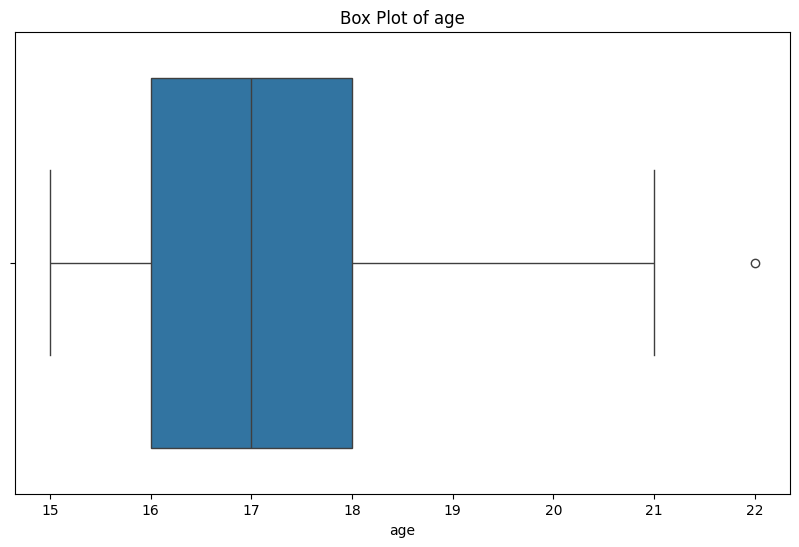

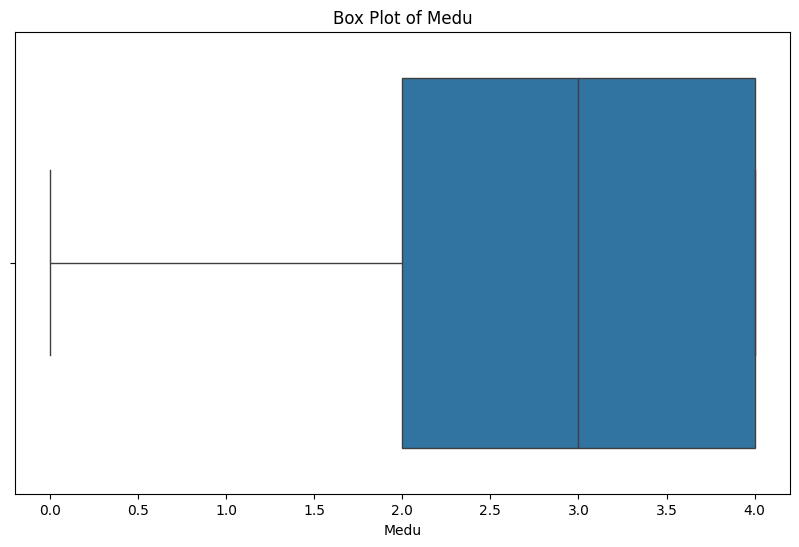

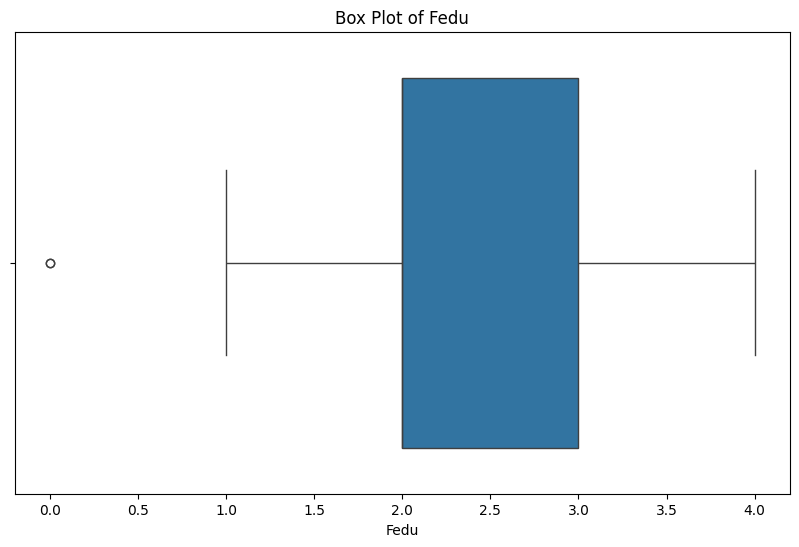

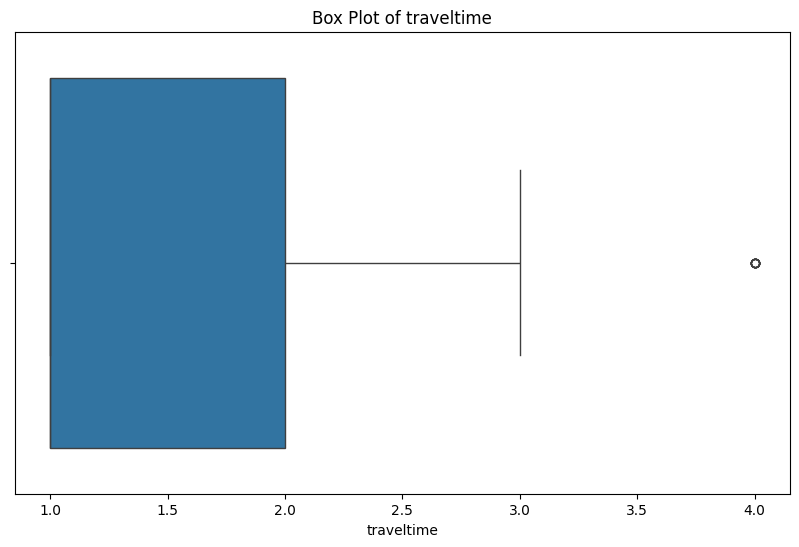

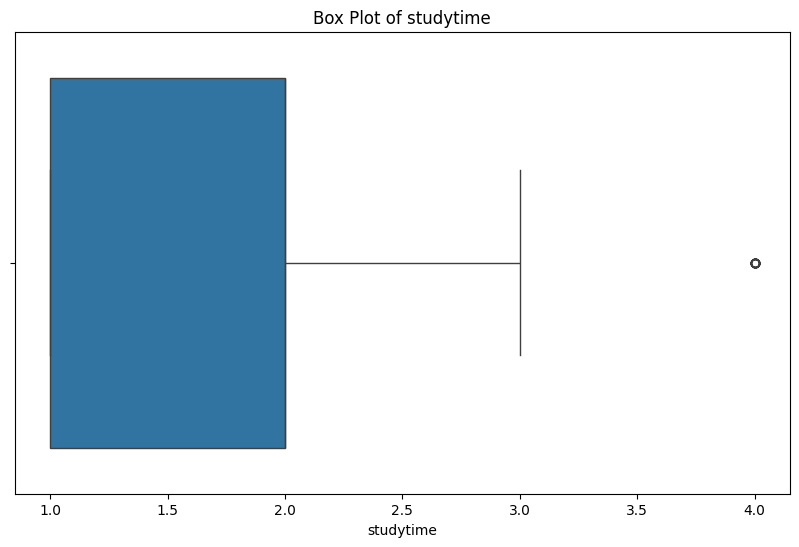

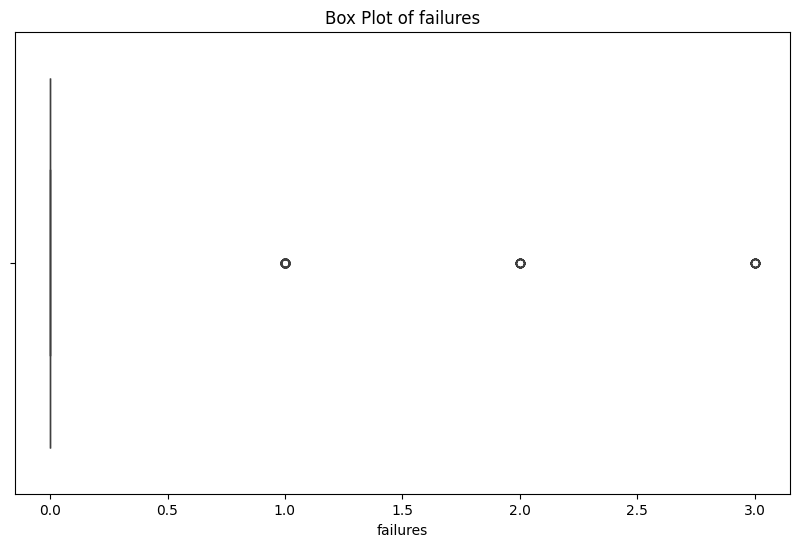

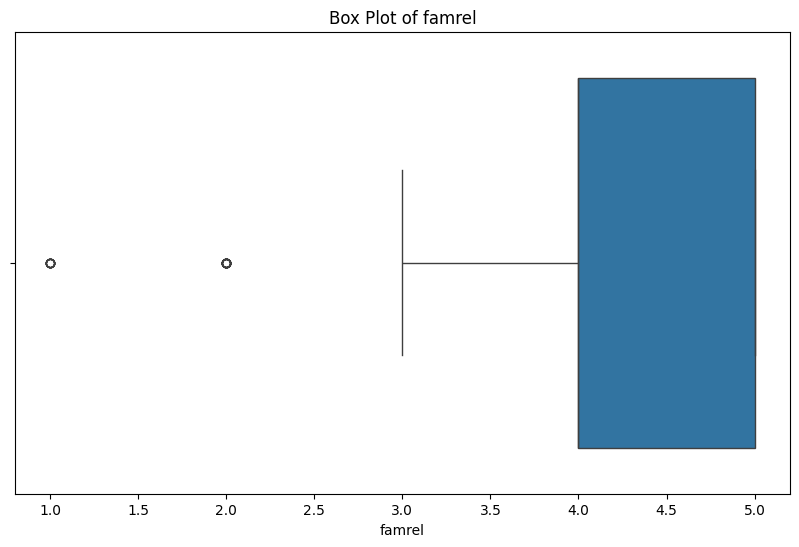

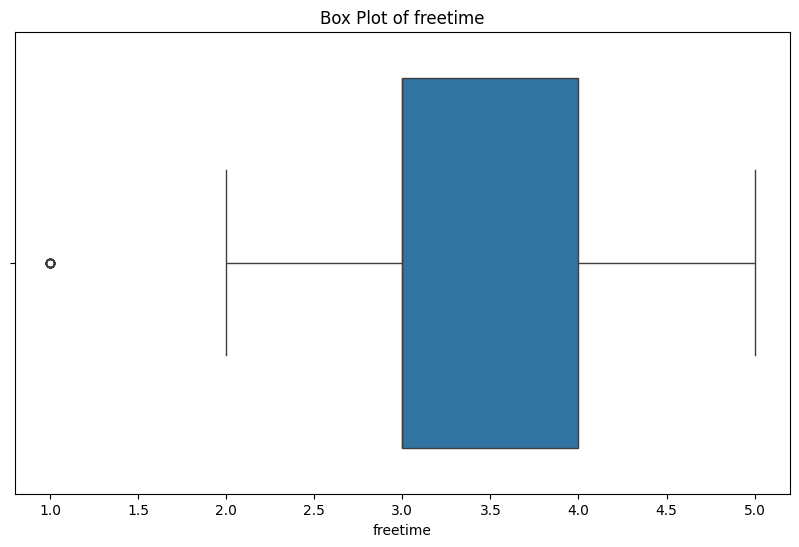

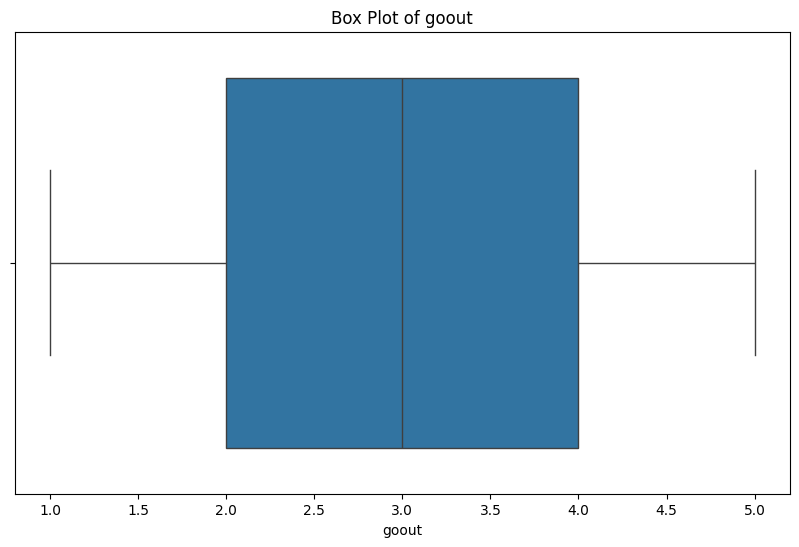

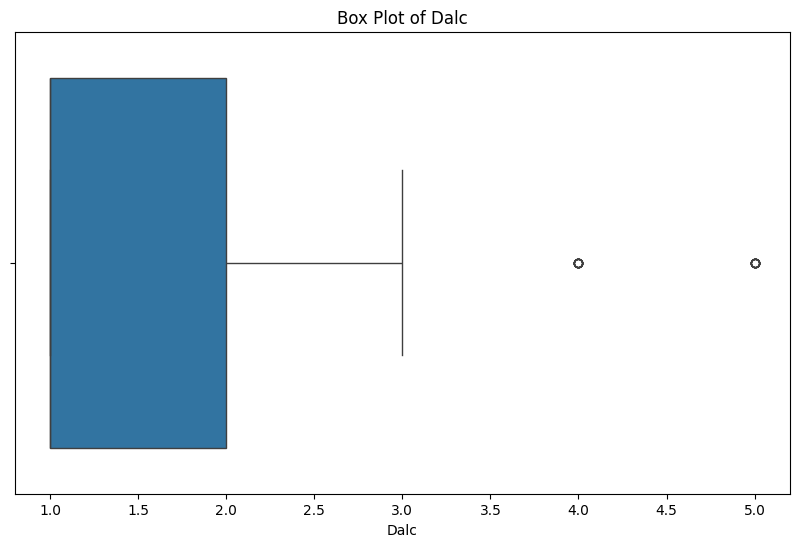

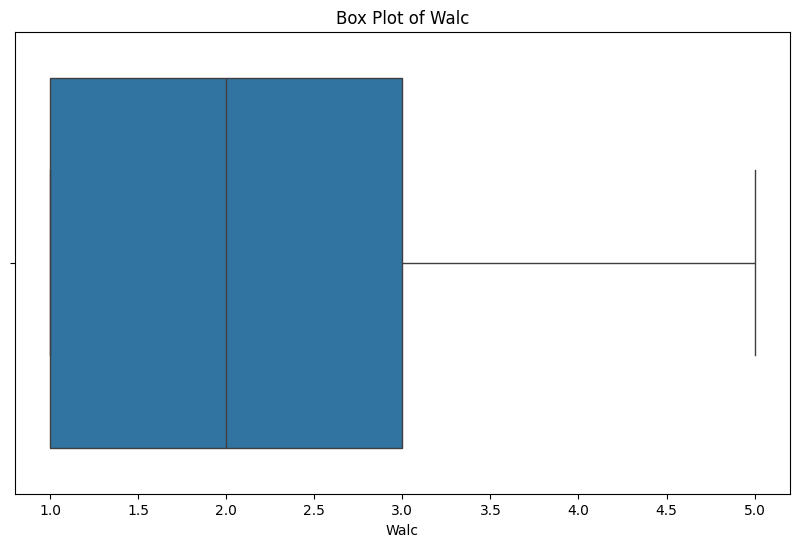

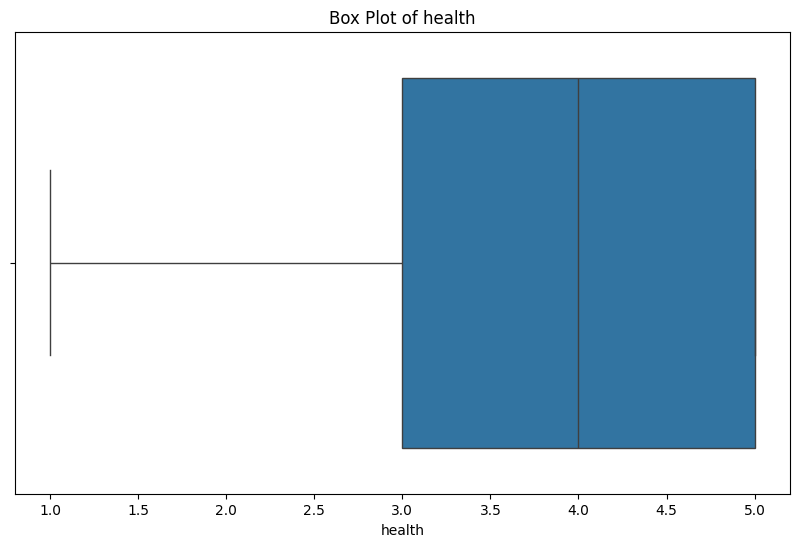

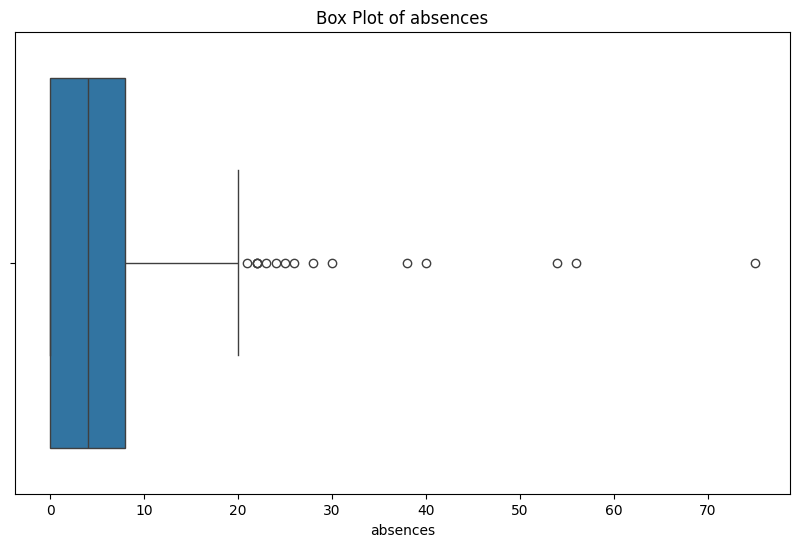

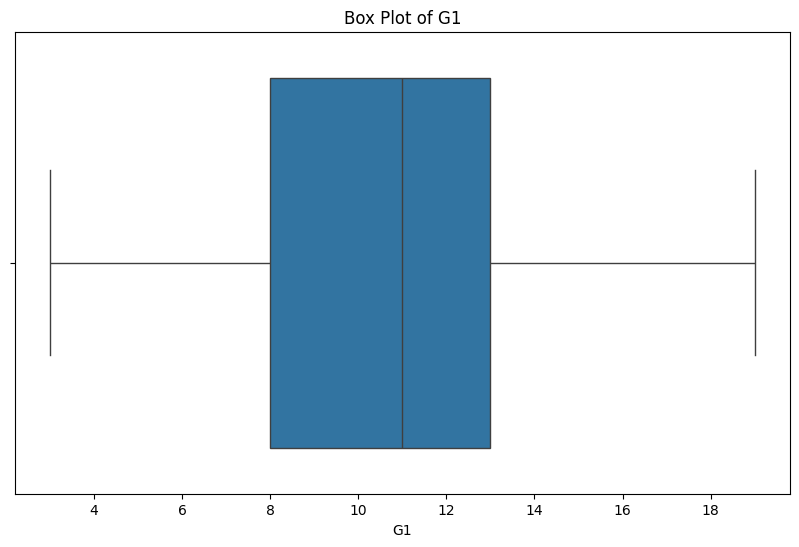

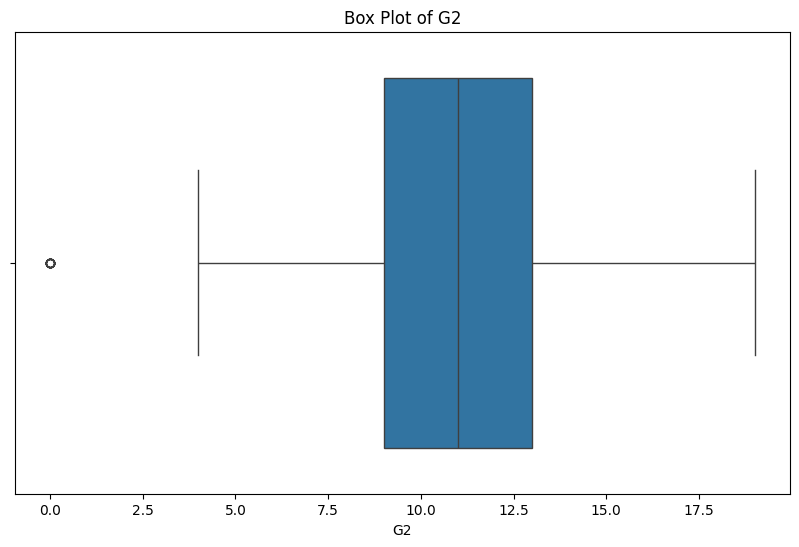

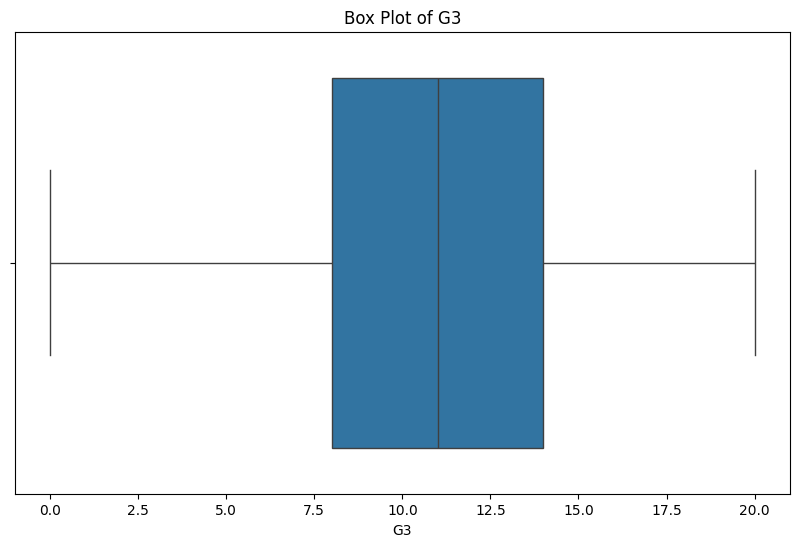

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [23]:
#Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [25]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [31]:
from sklearn.preprocessing import StandardScaler
# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

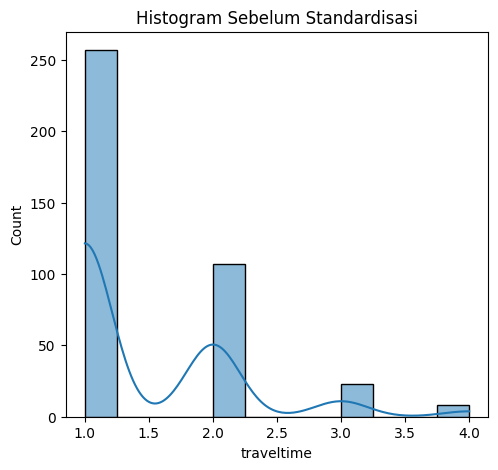

In [32]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

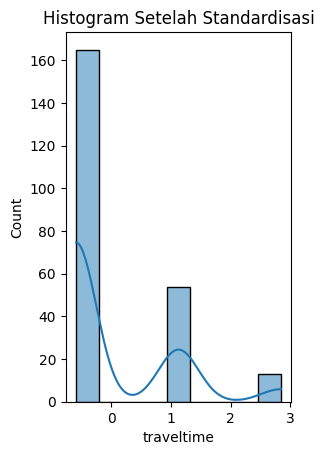

In [38]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [39]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()
print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [age, Medu, Fedu, traveltime, studytime, failures, famrel, freetime, goout, Dalc, Walc, health, absences, G1, G2, G3, school, sex, address, famsize, Pstatus, Mjob, Fjob, reason, guardian, schoolsup, famsup, paid, activities, nursery, higher, internet, romantic]
Index: []

[0 rows x 33 columns]


In [40]:
# Menghapus baris duplikat
df = df.drop_duplicates()
print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
          age      Medu      Fedu  traveltime  studytime  failures    famrel  \
0    1.370659  1.047883  1.240231    1.126947   0.062721       0.0 -0.167605   
1    0.469829 -1.714718 -1.608617   -0.593130   0.062721       0.0  1.272556   
3   -1.331830  1.047883 -0.659001   -0.593130   1.517846       0.0 -1.607766   
4   -0.431001  0.127016  0.290615   -0.593130   0.062721       0.0 -0.167605   
5   -0.431001  1.047883  0.290615   -0.593130   0.062721       0.0  1.272556   
..        ...       ...       ...         ...        ...       ...       ...   
385  1.370659 -0.793851 -0.659001    1.126947   1.517846       0.0  1.272556   
386  1.370659  1.047883  1.240231    2.847023  -1.392404       0.0 -0.167605   
388  1.370659  0.127016 -1.608617   -0.593130   0.062721       0.0 -0.167605   
393  1.370659  0.127016 -0.659001    2.847023  -1.392404       0.0 -0.167605   
394  2.271489 -1.714718 -1.608617   -0.593130  -1.392404       0.0 -1.607766   

 

In [41]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
0,GP,F,U,GT3,A,at_home,teacher,course,mother,yes,no,no,no,yes,yes,no,no
1,GP,F,U,GT3,T,at_home,other,course,father,no,yes,no,no,no,yes,yes,no
3,GP,F,U,GT3,T,health,services,home,mother,no,yes,yes,yes,yes,yes,yes,yes
4,GP,F,U,GT3,T,other,other,home,father,no,yes,yes,no,yes,yes,no,no
5,GP,M,U,LE3,T,services,other,reputation,mother,no,yes,yes,yes,yes,yes,yes,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
385,MS,F,R,GT3,T,at_home,other,other,mother,no,no,yes,no,yes,yes,no,no
386,MS,F,R,GT3,T,teacher,at_home,reputation,mother,no,yes,yes,yes,yes,yes,yes,yes
388,MS,F,U,LE3,T,teacher,services,course,mother,no,yes,yes,no,yes,yes,yes,no
393,MS,M,R,LE3,T,services,other,course,mother,no,no,no,no,no,yes,yes,no


In [42]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,1.370659,1.047883,1.240231,1.126947,0.062721,0.0,-0.167605,-0.355756,0.992052,-0.500192,...,True,False,False,True,False,True,True,False,True,False
1,0.469829,-1.714718,-1.608617,-0.593130,0.062721,0.0,1.272556,-0.355756,0.016814,-0.500192,...,True,False,True,False,False,True,False,True,True,False
3,-1.331830,1.047883,-0.659001,-0.593130,1.517846,0.0,-1.607766,-1.534835,-0.958423,-0.500192,...,False,True,False,True,False,True,False,True,False,True
4,-0.431001,0.127016,0.290615,-0.593130,0.062721,0.0,-0.167605,-0.355756,-0.958423,-0.500192,...,True,False,False,True,False,True,True,False,True,False
5,-0.431001,1.047883,0.290615,-0.593130,0.062721,0.0,1.272556,0.823322,-0.958423,-0.500192,...,False,True,False,True,False,True,False,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
385,1.370659,-0.793851,-0.659001,1.126947,1.517846,0.0,1.272556,-0.355756,0.016814,-0.500192,...,True,False,False,True,False,True,True,False,True,False
386,1.370659,1.047883,1.240231,2.847023,-1.392404,0.0,-0.167605,0.823322,0.016814,1.285110,...,False,True,False,True,False,True,False,True,False,True
388,1.370659,0.127016,-1.608617,-0.593130,0.062721,0.0,-0.167605,-0.355756,0.992052,-0.500192,...,True,False,False,True,False,True,False,True,True,False
393,1.370659,0.127016,-0.659001,2.847023,-1.392404,0.0,-0.167605,0.823322,-1.933661,3.070412,...,True,False,True,False,False,True,False,True,True,False


In [43]:
from sklearn.preprocessing import LabelEncoder
# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)
for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])# Menampilkan hasil
df_lencoder

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
0,1.370659,1.047883,1.240231,1.126947,0.062721,0.0,-0.167605,-0.355756,0.992052,-0.500192,...,0,1,1,0,0,0,1,1,0,0
1,0.469829,-1.714718,-1.608617,-0.593130,0.062721,0.0,1.272556,-0.355756,0.016814,-0.500192,...,0,0,0,1,0,0,0,1,1,0
3,-1.331830,1.047883,-0.659001,-0.593130,1.517846,0.0,-1.607766,-1.534835,-0.958423,-0.500192,...,1,1,0,1,1,1,1,1,1,1
4,-0.431001,0.127016,0.290615,-0.593130,0.062721,0.0,-0.167605,-0.355756,-0.958423,-0.500192,...,1,0,0,1,1,0,1,1,0,0
5,-0.431001,1.047883,0.290615,-0.593130,0.062721,0.0,1.272556,0.823322,-0.958423,-0.500192,...,3,1,0,1,1,1,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
385,1.370659,-0.793851,-0.659001,1.126947,1.517846,0.0,1.272556,-0.355756,0.016814,-0.500192,...,2,1,0,0,1,0,1,1,0,0
386,1.370659,1.047883,1.240231,2.847023,-1.392404,0.0,-0.167605,0.823322,0.016814,1.285110,...,3,1,0,1,1,1,1,1,1,1
388,1.370659,0.127016,-1.608617,-0.593130,0.062721,0.0,-0.167605,-0.355756,0.992052,-0.500192,...,0,1,0,1,1,0,1,1,1,0
393,1.370659,0.127016,-0.659001,2.847023,-1.392404,0.0,-0.167605,0.823322,-1.933661,3.070412,...,0,1,0,0,0,0,0,1,1,0


EDA & ExDA

In [44]:
df_lencoder.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
0,1.370659,1.047883,1.240231,1.126947,0.062721,0.0,-0.167605,-0.355756,0.992052,-0.500192,...,0,1,1,0,0,0,1,1,0,0
1,0.469829,-1.714718,-1.608617,-0.593130,0.062721,0.0,1.272556,-0.355756,0.016814,-0.500192,...,0,0,0,1,0,0,0,1,1,0
3,-1.331830,1.047883,-0.659001,-0.593130,1.517846,0.0,-1.607766,-1.534835,-0.958423,-0.500192,...,1,1,0,1,1,1,1,1,1,1
4,-0.431001,0.127016,0.290615,-0.593130,0.062721,0.0,-0.167605,-0.355756,-0.958423,-0.500192,...,1,0,0,1,1,0,1,1,0,0
5,-0.431001,1.047883,0.290615,-0.593130,0.062721,0.0,1.272556,0.823322,-0.958423,-0.500192,...,3,1,0,1,1,1,1,1,1,0


In [45]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)
missing_data[missing_data['Missing Values'] > 0]  # Menampilkan kolom dengan missing values

,Missing Values,Percentage


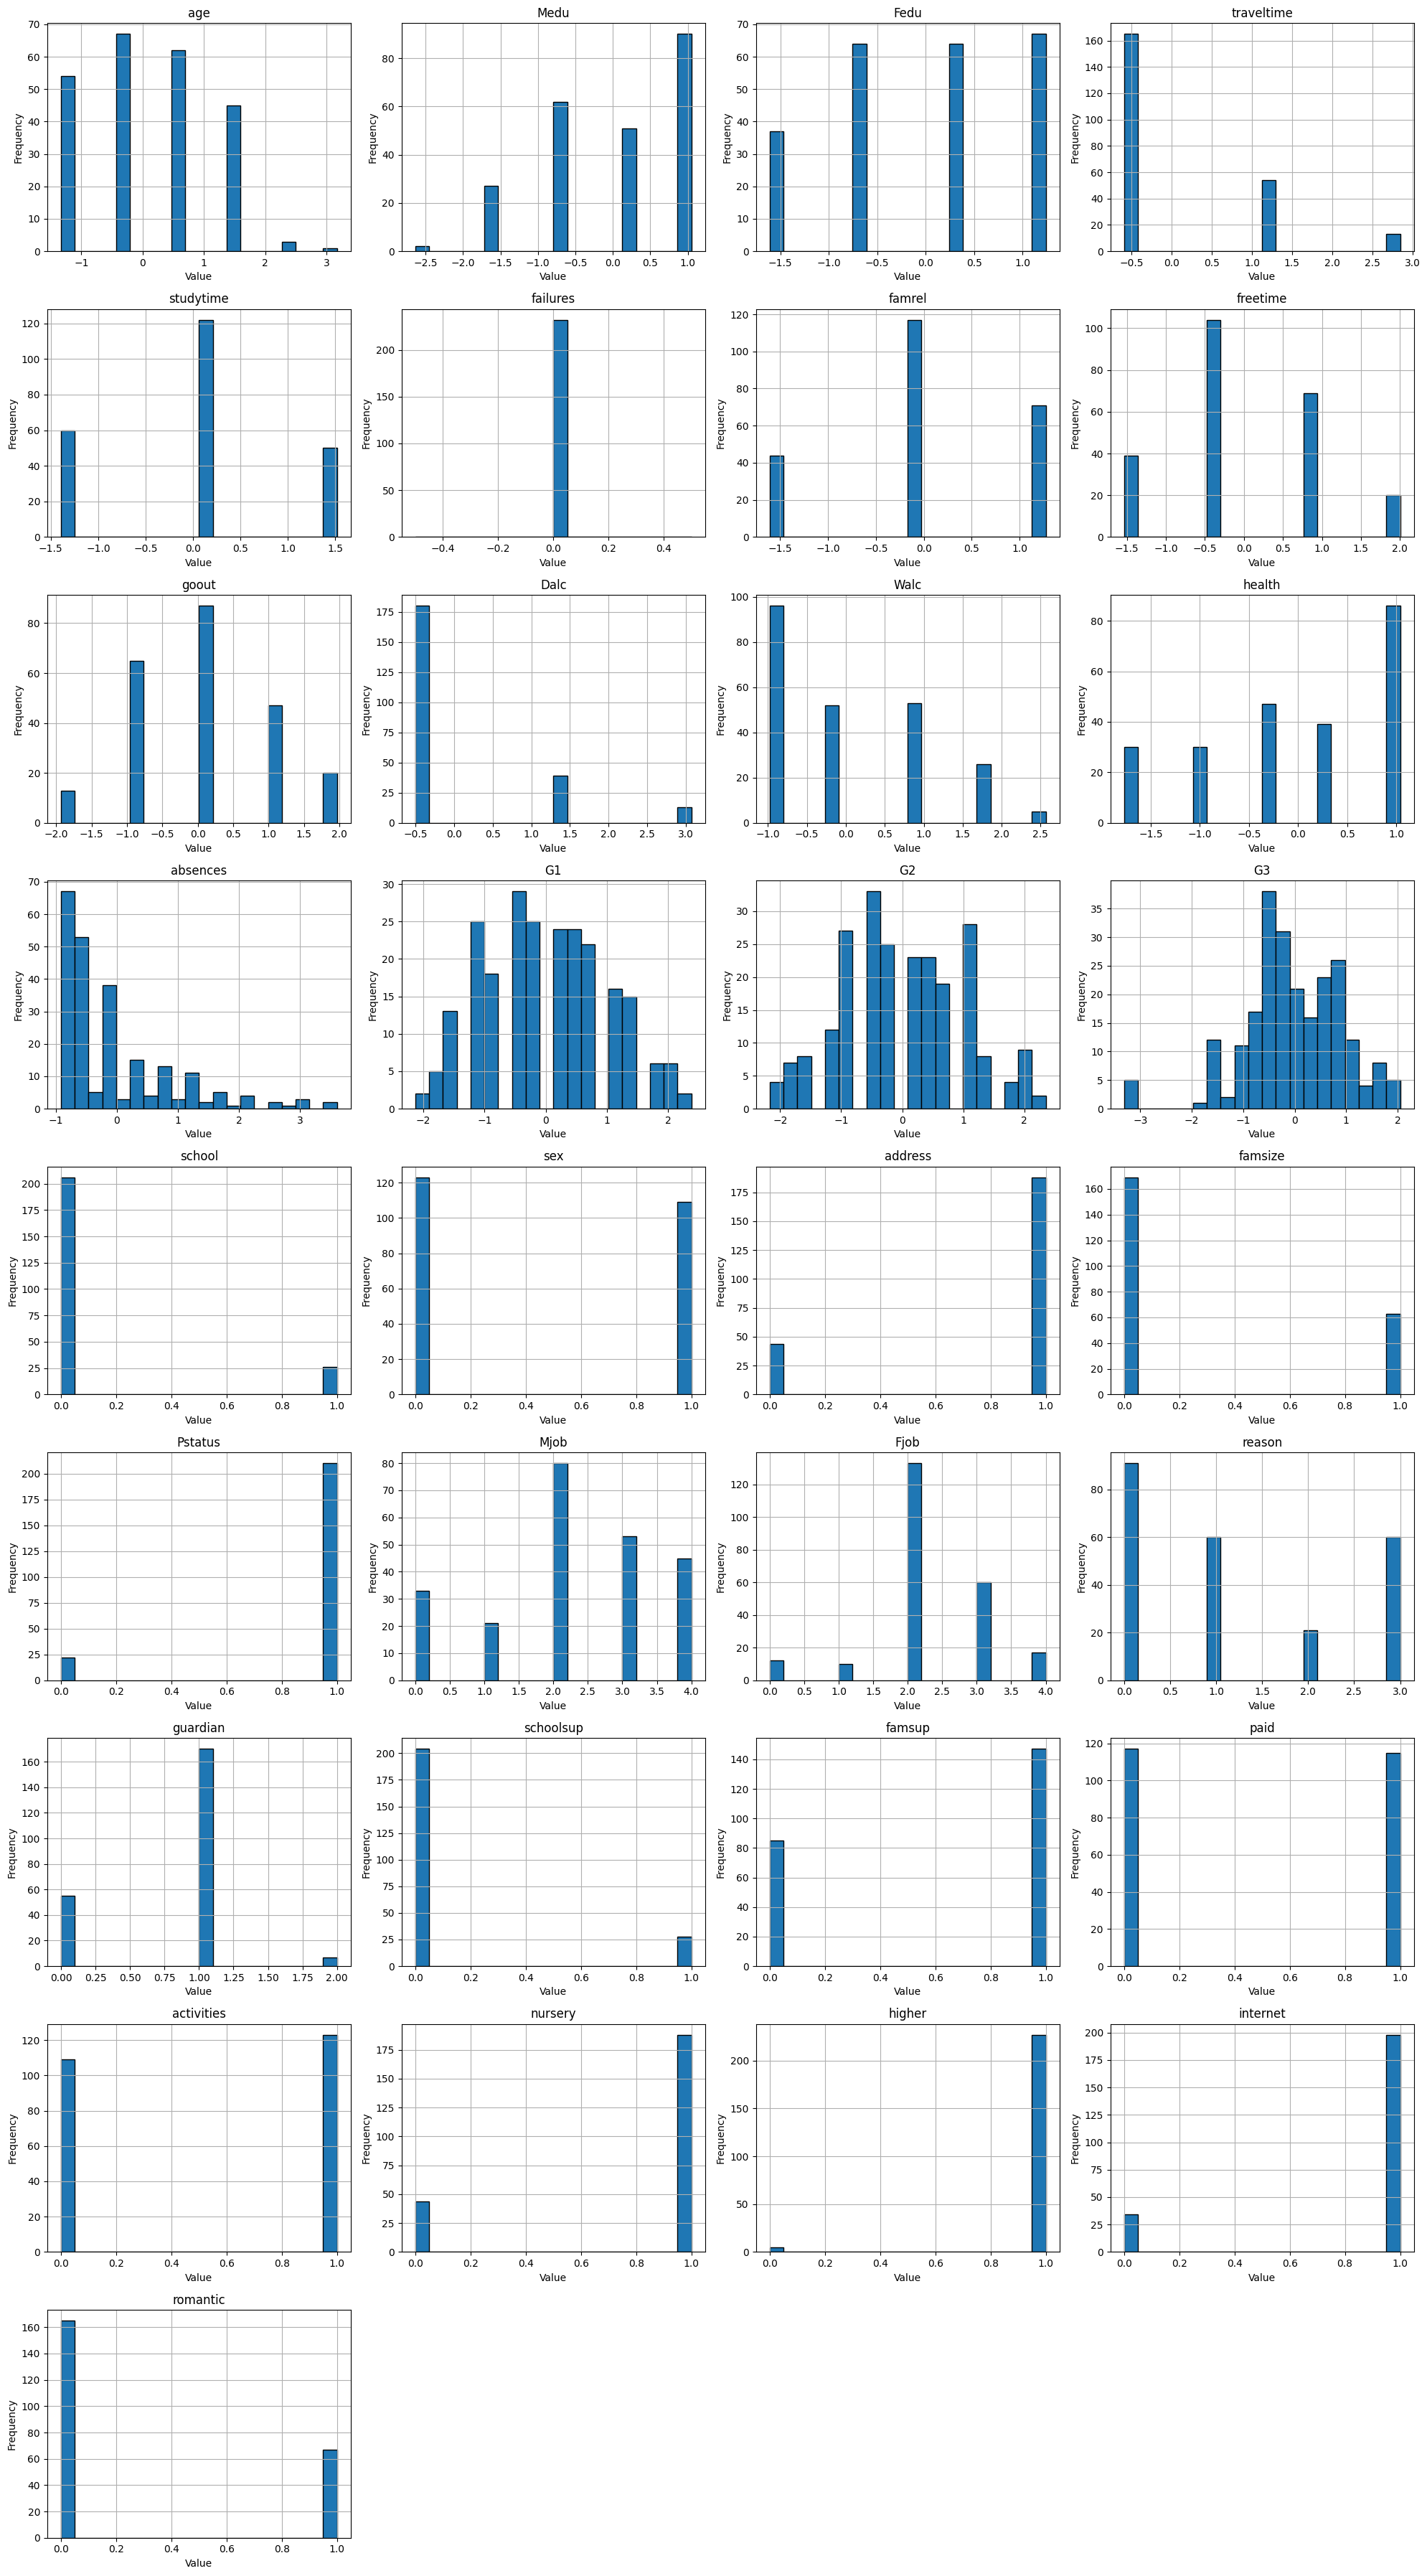

In [47]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]
# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4 # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols)# Ceiling division untuk menentukan jumlah baris
# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')
# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()


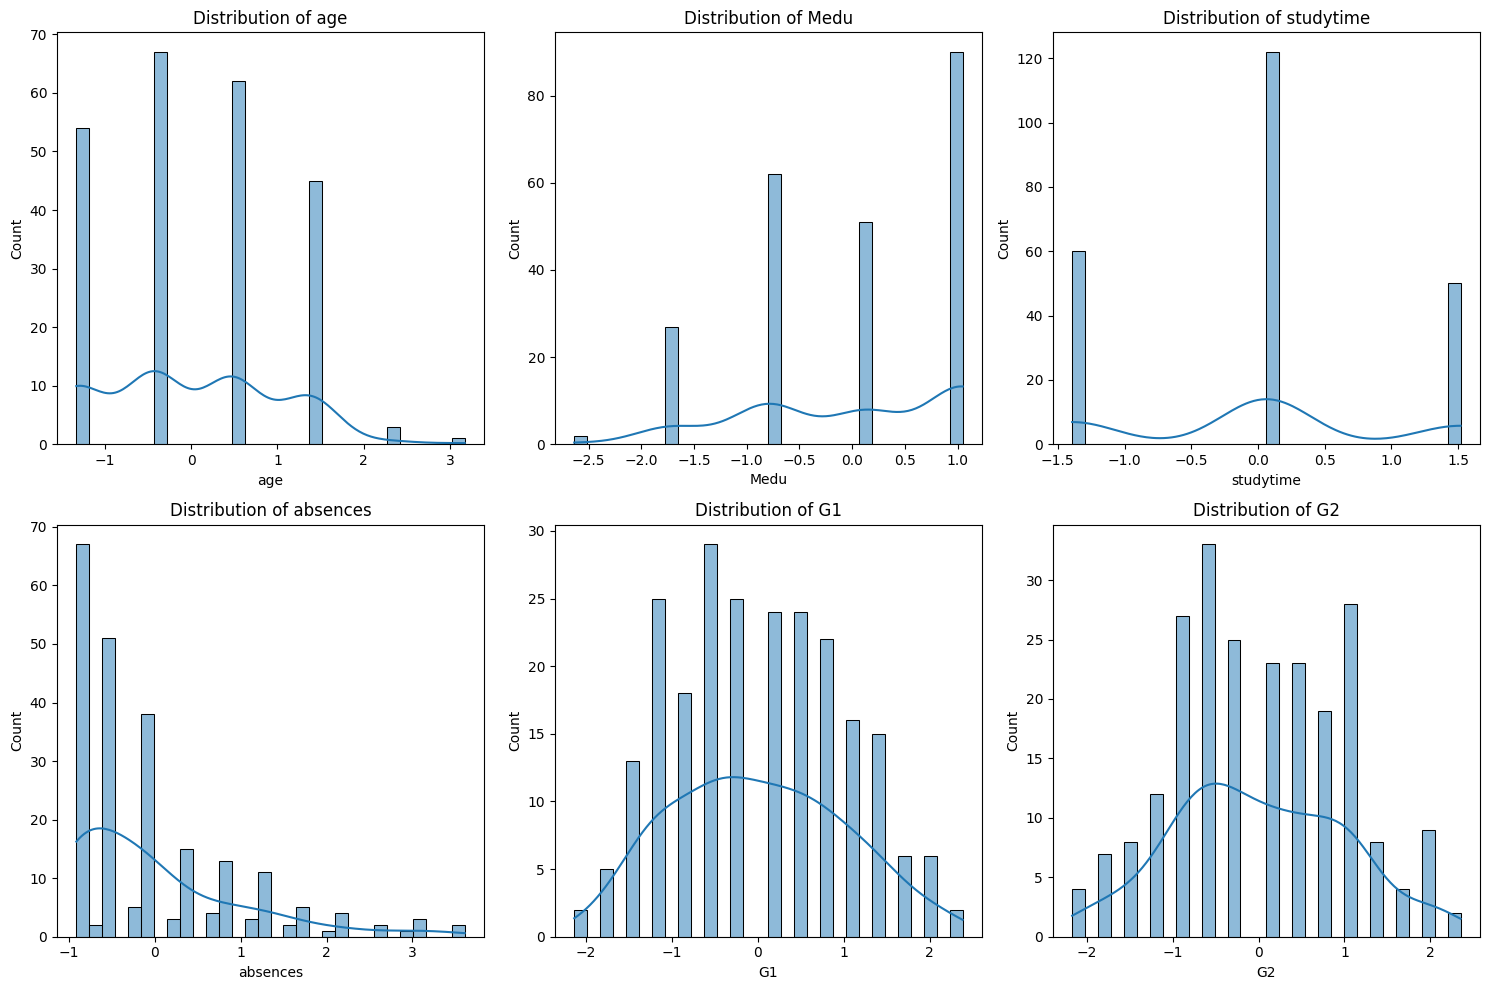

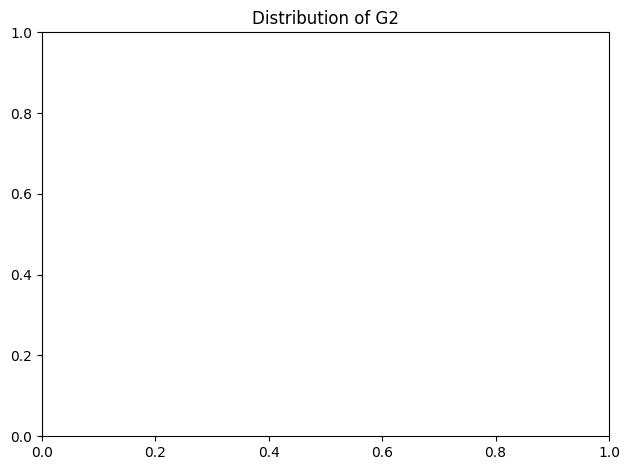

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
# Visualisasi distribusi data untuk beberapa kolom
    # Use columns that exist in this dataset
columns_to_plot = ['age', 'Medu', 'studytime', 'absences', 'G1', 'G2']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')
plt.tight_layout()
plt.show()
plt.title(f'Distribution of {column}')
plt.tight_layout()
plt.show()

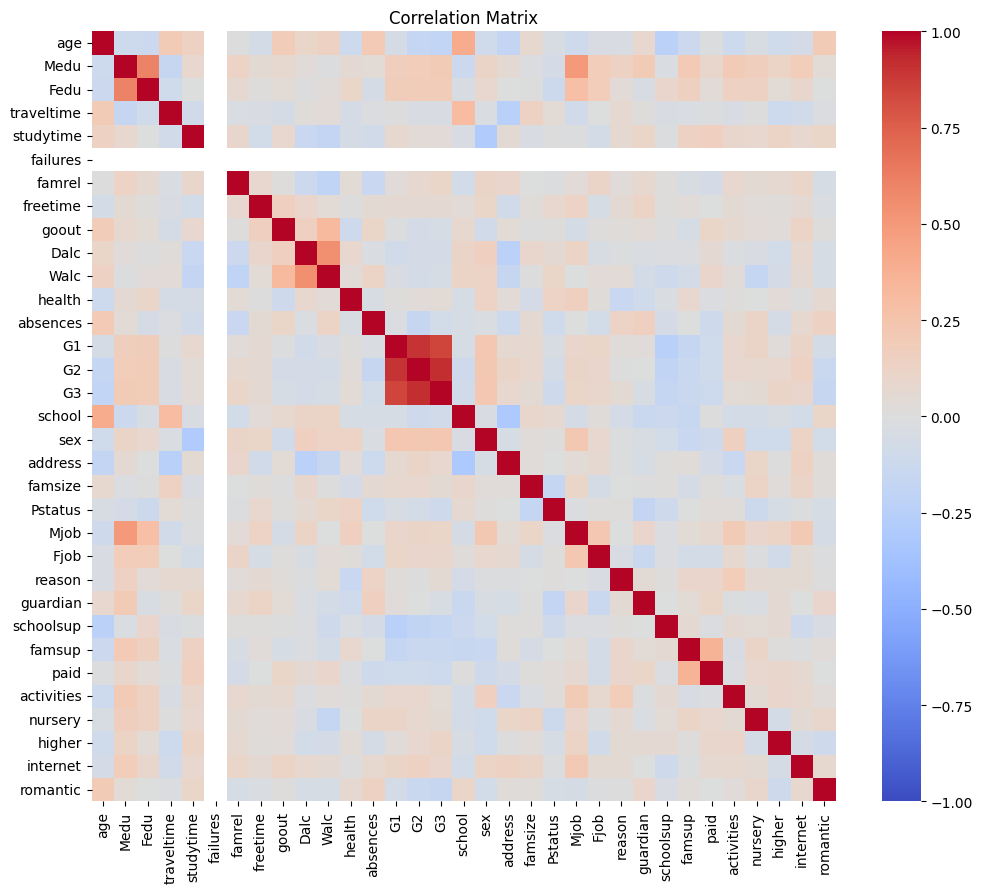

In [ ]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

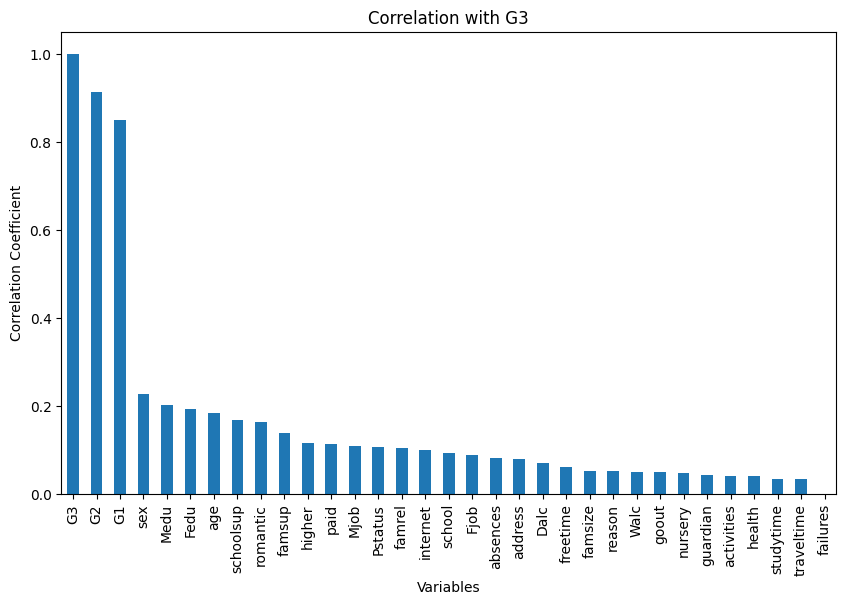

In [54]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['G3']
# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with G3')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

LATIHAN: DATA SPLITTING

In [55]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['G3'])
y = df_lencoder['G3'] 

In [56]:
from sklearn.model_selection import train_test_split
# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)


In [57]:
# menghitung panjang/jumlah data 
print("Jumlah data: ",len(X))
# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ",len(x_test))

Jumlah data:  232
Jumlah data latih:  185
Jumlah data test:  47
